In [29]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
random.seed(12)

In [30]:
N = 1000
K = 3
# Class 1 parameters
weights1 = [0.40, 0.35, 0.25]
means1 = [              # Mean vectors
    [-4, -2],
    [0, 3],
    [4, -1]
]
# Class 2 parameters
weights2 = [0.30, 0.40, 0.30]
means2 = [              # Mean vectors     
    [-3, 3],
    [1, -3],
    [5, 3]
]

In [31]:
def standard_normal():
    u1 = random.random()   # Generate 2 uniform random numbers between 0 and 1
    u2 = random.random()
    while u1 == 0:         # Avoiding logarithm of zero
        u1 = random.random()

    z1 = math.sqrt(-2 * math.log(u1)) * math.cos(2 * math.pi * u2)
    z2 = math.sqrt(-2 * math.log(u1)) * math.sin(2 * math.pi * u2)
    return z1, z2

In [32]:
def generate_gaussian(mean, covariance):
    z1, z2 = standard_normal()
    a = covariance[0][0]
    b = covariance[0][1]
    c = covariance[1][1]

    if a <= 0 or c - (b * b / a) <= 0:       # Check that the covariance matrix is positive definite
        raise ValueError("Covariance matrix must be positive definite")

    x1 = mean[0] + math.sqrt(a) * z1         # Generate the 1st coordinate using mean and variance
    x2 = (mean[1] + (b / math.sqrt(a)) * z1 + math.sqrt(c - (b * b / a)) * z2)        # Generate the 2nd coordinate including the covariance effect

    return [x1, x2]

In [33]:
def generate_data(N, weights, means, covariances):
    data = []
    component_labels = []

    for _ in range(N):
        u = random.random()

        if u < weights[0]:        # Select 1st component
            component = 0
        elif u < weights[0] + weights[1]:       # Select 2nd component
            component = 1
        else:                      # Select 3rd component
            component = 2

        point = generate_gaussian(       # Generate a point using component
            means[component],
            covariances[component]
        )

        data.append(point)
        component_labels.append(component)

    return data, component_labels

In [34]:
covariance_types = {
    "Spherical": [
        [[1, 0], [0, 1]],
        [[1, 0], [0, 1]],
        [[1, 0], [0, 1]]
    ],

    "Diagonal": [
        [[2, 0], [0, 0.5]],
        [[0.5, 0], [0, 2]],
        [[1.5, 0], [0, 0.7]]
    ],

    "Full": [
        [[2, 0.8], [0.8, 1]],
        [[1.5, -0.6], [-0.6, 1]],
        [[1, 0.5], [0.5, 1.5]]
    ]
}

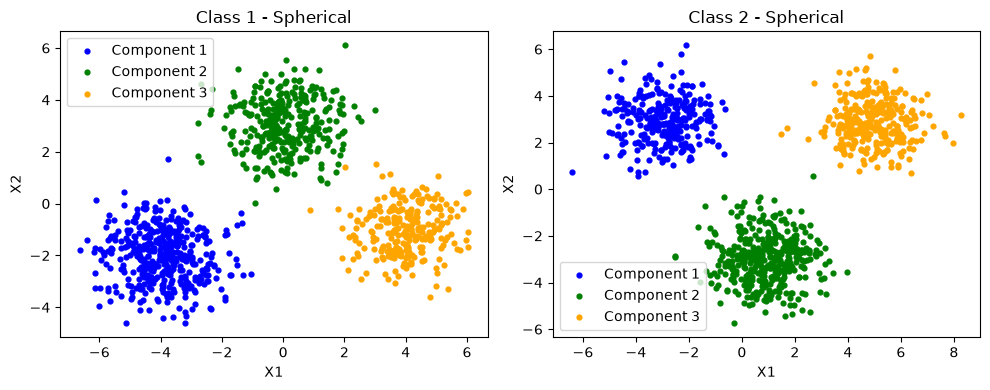

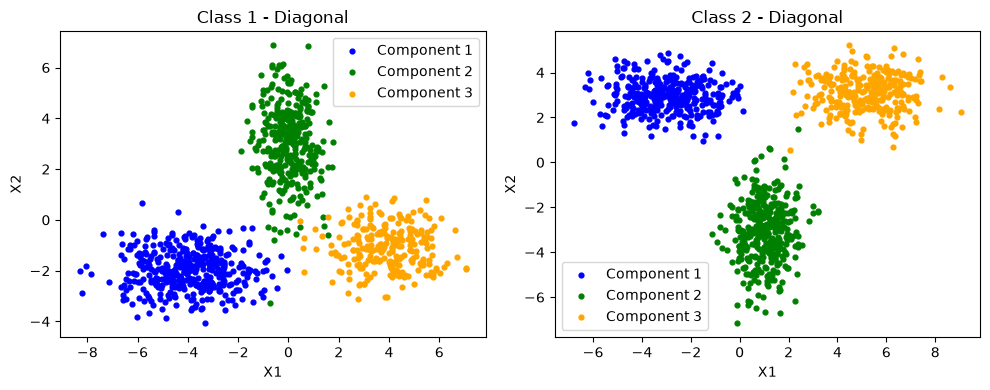

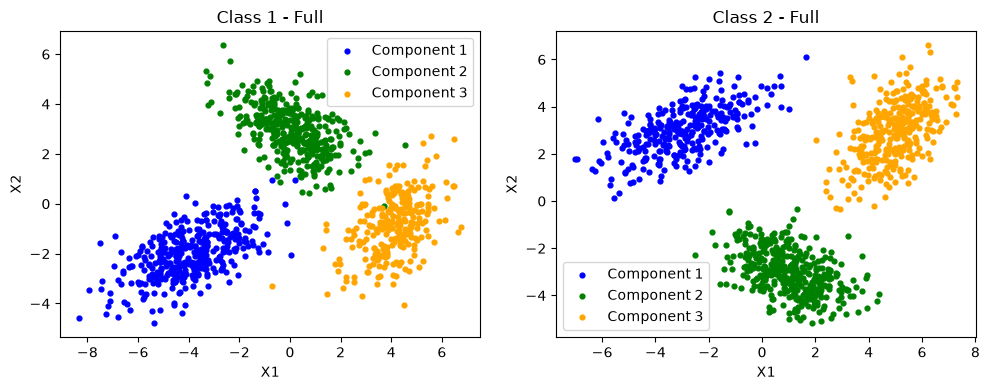

In [35]:
generated_data = {}

component_colors = ["blue", "green", "orange"]

for name, covariances in covariance_types.items():

    class1, labels1 = generate_data(
        N, weights1, means1, covariances
    )

    class2, labels2 = generate_data(
        N, weights2, means2, covariances
    )

    generated_data[name] = {
        "Class 1": class1,
        "Class 2": class2,
        "Labels 1": labels1,
        "Labels 2": labels2
    }

    class1 = np.array(class1)      # Convert point lists into NumPy arrays
    class2 = np.array(class2)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    for component in range(3):
        mask1 = np.array(labels1) == component
        mask2 = np.array(labels2) == component

        axes[0].scatter(
            class1[mask1, 0], class1[mask1, 1],
            color=component_colors[component],
            s=12, label=f"Component {component + 1}"
        )

        axes[1].scatter(
            class2[mask2, 0], class2[mask2, 1],
            color=component_colors[component],
            s=12, label=f"Component {component + 1}"
        )

    axes[0].set_title("Class 1 - " + name)
    axes[1].set_title("Class 2 - " + name)

    for ax in axes:
        ax.set_xlabel("X1")
        ax.set_ylabel("X2")
        ax.legend()

    plt.tight_layout()
    plt.show()

In [36]:
def train_test_split(data, train_ratio=0.8):
    data = list(data)
    random.shuffle(data)

    split_index = int(len(data) * train_ratio)         #80% training portion

    train_data = data[:split_index]
    test_data = data[split_index:]

    return train_data, test_data

datasets = {}
for name in covariance_types:
    class1 = generated_data[name]["Class 1"]       # Retrieve the two generated classe
    class2 = generated_data[name]["Class 2"]

    train1, test1 = train_test_split(class1)       # Split each class independently
    train2, test2 = train_test_split(class2)

    datasets[name] = {
        "train1": train1,
        "test1": test1,
        "train2": train2,
        "test2": test2
    }
    print("\n", name)
    print("Class 1 - Training:", len(train1), "Testing:", len(test1))
    print("Class 2 - Training:", len(train2), "Testing:", len(test2))


 Spherical
Class 1 - Training: 800 Testing: 200
Class 2 - Training: 800 Testing: 200

 Diagonal
Class 1 - Training: 800 Testing: 200
Class 2 - Training: 800 Testing: 200

 Full
Class 1 - Training: 800 Testing: 200
Class 2 - Training: 800 Testing: 200


In [37]:
def euclidean_distance_squared(point1, point2):             #Calculate the squared Euclidean distance between two points
    return ((point1[0] - point2[0]) ** 2 + (point1[1] - point2[1]) ** 2)

def kmeans(data, k=3, max_iterations=100):
    data = [list(point) for point in data]     # Convert all points to lists
    centroids = [list(random.choice(data))]     # Select the first centroid randomly

    while len(centroids) < k:
        distances = []

        for point in data:               # Find the distance to the nearest existing centroid
            nearest_distance = min(euclidean_distance_squared(point, centroid) for centroid in centroids)
            distances.append(nearest_distance)

        farthest_index = distances.index(max(distances))       # Choose the point with the largest nearest-centroid distance
        centroids.append(list(data[farthest_index]))

    for iteration in range(max_iterations):
        clusters = [[] for _ in range(k)]

        # Assign each point to its nearest centroid
        for point in data:
            distances = [euclidean_distance_squared(point, centroid) for centroid in centroids]
            cluster_index = distances.index(min(distances))
            clusters[cluster_index].append(point)

        # Update centroids
        new_centroids = []

        for i in range(k):
            if len(clusters[i]) == 0:
                new_centroids.append(centroids[i])
            else:
                mean_x = sum(p[0] for p in clusters[i]) / len(clusters[i])
                mean_y = sum(p[1] for p in clusters[i]) / len(clusters[i])
                new_centroids.append([mean_x, mean_y])

        # Measure the maximum squared centroid movement
        change = max(euclidean_distance_squared(centroids[i], new_centroids[i]) for i in range(k))
        centroids = new_centroids

        if change < 1e-8:
            break

    return centroids

In [38]:
kmeans_models = {}
for name in covariance_types:
    train1 = datasets[name]["train1"]
    train2 = datasets[name]["train2"]

    centroids1 = kmeans(train1, k=3)   # Fit K-means independently to Class 1
    centroids2 = kmeans(train2, k=3)   # Fit K-means independently to Class 2
 
    kmeans_models[name] = {
        "Class 1": centroids1,
        "Class 2": centroids2
    }

    print("\n", name)
    print("Class 1 centroids:")
    for centroid in centroids1:
        print([round(v, 3) for v in centroid])

    print("Class 2 centroids:")
    for centroid in centroids2:
        print([round(v, 3) for v in centroid])


 Spherical
Class 1 centroids:
[0.01, 3.019]
[-3.921, -1.958]
[4.016, -0.993]
Class 2 centroids:
[-2.941, 2.954]
[4.961, 2.873]
[0.867, -3.01]

 Diagonal
Class 1 centroids:
[3.895, -1.121]
[-3.933, -1.937]
[-0.037, 3.169]
Class 2 centroids:
[-2.995, 2.963]
[5.195, 3.104]
[1.031, -3.048]

 Full
Class 1 centroids:
[0.014, 2.84]
[-3.916, -2.004]
[4.083, -0.709]
Class 2 centroids:
[-2.981, 3.033]
[1.083, -3.036]
[4.923, 2.992]


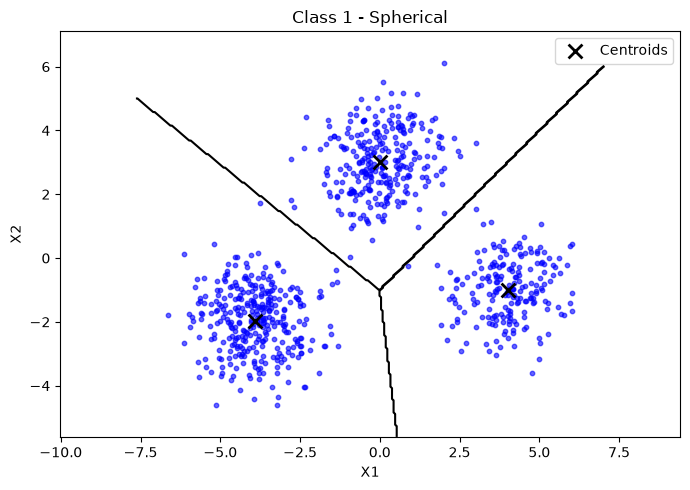

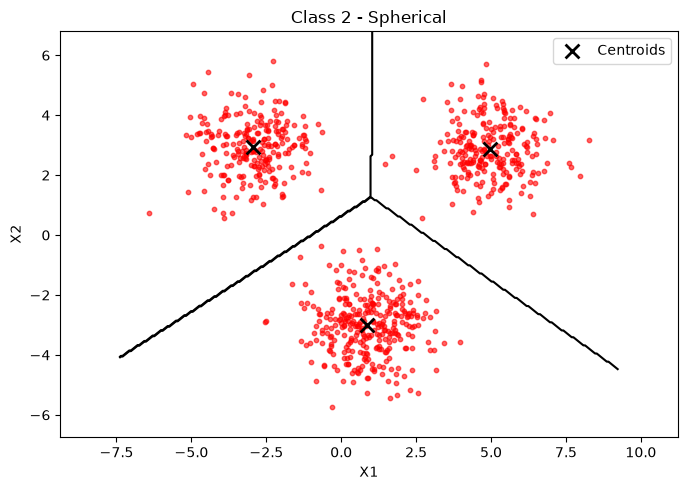

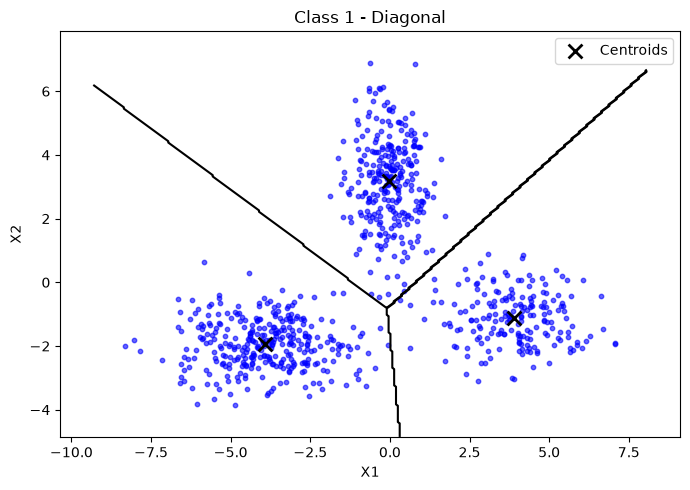

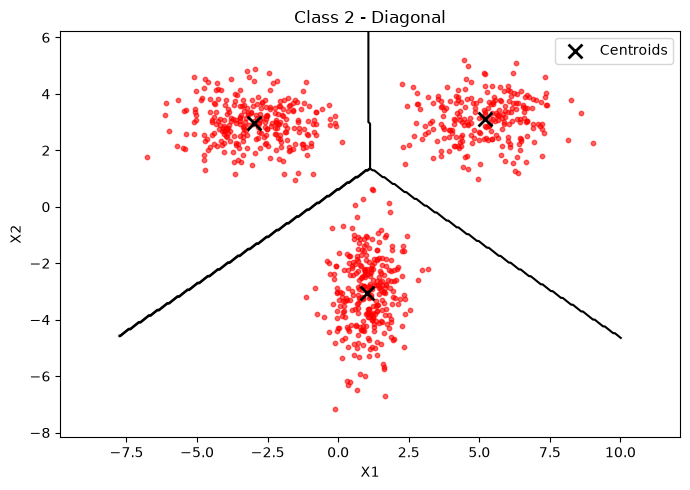

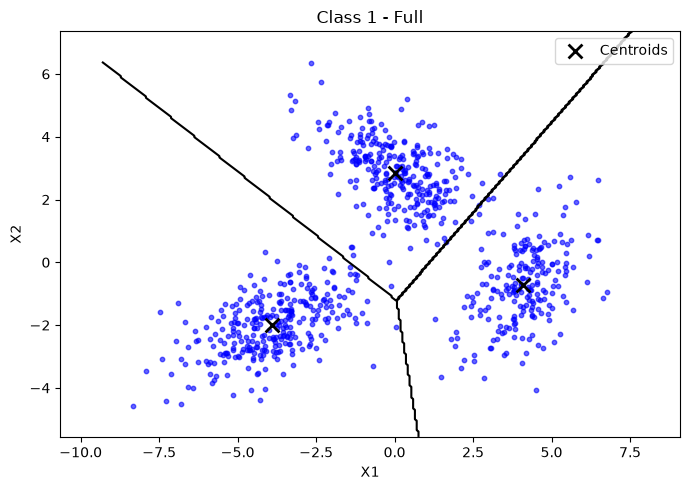

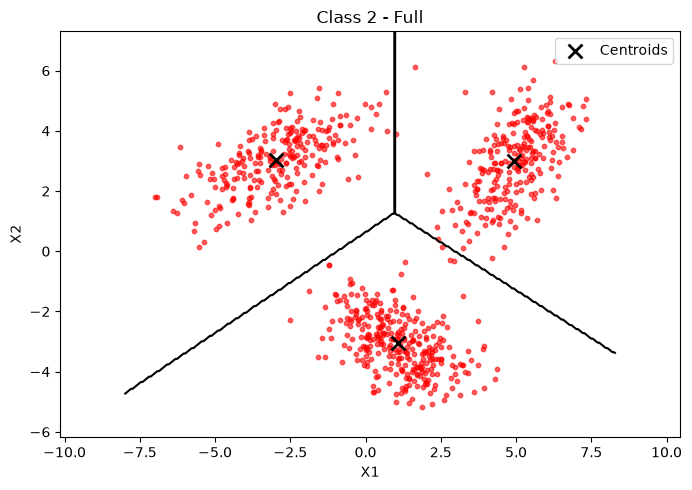

In [39]:
def predict_cluster(point, centroids):       # distance from the point to each centroid
    distances = [
        euclidean_distance_squared(point, centroid)
        for centroid in centroids
    ]
    return distances.index(min(distances))   # Return the index of the nearest centroid


def plot_cluster_boundaries(data, centroids, class_name,
                            covariance_name, point_color):

    data = np.array(data)
    centroids = np.array(centroids)

    x_min = data[:, 0].min() - 1
    x_max = data[:, 0].max() + 1
    y_min = data[:, 1].min() - 1
    y_max = data[:, 1].max() + 1

    # Create a grid of coordinates over the plotting area
    xx, yy = np.meshgrid(              
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid_points = np.column_stack((xx.ravel(), yy.ravel()))       # Combine the grid coordinates into 2D points

    # Assign each grid point to its nearest centroid
    predictions = [
        predict_cluster(point, centroids)
        for point in grid_points
    ]

    Z = np.array(predictions).reshape(xx.shape)

    plt.figure(figsize=(7, 5))

    # Draw boundaries between nearest-centroid regions
    plt.contour(
        xx, yy, Z,
        levels=[0.5, 1.5],
        colors="black",
        linewidths=1.5
    )

    plt.scatter(
        data[:, 0], data[:, 1],
        color=point_color, s=10, alpha=0.6
    )

    plt.scatter(
        centroids[:, 0], centroids[:, 1],
        color="black", marker="x", s=100,
        linewidths=2, label="Centroids"
    )

    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.title(class_name + " - " + covariance_name)
    plt.axis("equal")
    plt.legend()
    plt.tight_layout()
    plt.show()


for name in covariance_types:

    plot_cluster_boundaries(
        datasets[name]["train1"],
        kmeans_models[name]["Class 1"],
        "Class 1",
        name,
        "blue"
    )

    plot_cluster_boundaries(
        datasets[name]["train2"],
        kmeans_models[name]["Class 2"],
        "Class 2",
        name,
        "red"
    )

In [40]:
def calculate_distortion(point, centroids):  # Find the squared distance from the point to every centroid
    distances = [
        euclidean_distance_squared(point, centroid)
        for centroid in centroids
    ]

    return min(distances)


def classify_point(point, centroids1, centroids2):
    distortion1 = calculate_distortion(point, centroids1)
    distortion2 = calculate_distortion(point, centroids2)

    if distortion1 < distortion2:
        return 1
    else:
        return 2


def evaluate_classification(test1, test2, centroids1, centroids2):

    actual_labels = [1] * len(test1) + [2] * len(test2)
    test_points = list(test1) + list(test2)

    predicted_labels = [
        classify_point(point, centroids1, centroids2)
        for point in test_points
    ]

    correct = sum(
        actual == predicted
        for actual, predicted in zip(actual_labels, predicted_labels)
    )

    accuracy = correct / len(actual_labels) * 100

    # Confusion matrix: rows = actual class, columns = predicted class
    confusion = [
        [
            sum(a == 1 and p == 1
                for a, p in zip(actual_labels, predicted_labels)),
            sum(a == 1 and p == 2
                for a, p in zip(actual_labels, predicted_labels))
        ],
        [
            sum(a == 2 and p == 1
                for a, p in zip(actual_labels, predicted_labels)),
            sum(a == 2 and p == 2
                for a, p in zip(actual_labels, predicted_labels))
        ]
    ]

    return accuracy, confusion, actual_labels, predicted_labels

In [41]:
results = {}

for name in covariance_types:

    test1 = datasets[name]["test1"]
    test2 = datasets[name]["test2"]

    centroids1 = kmeans_models[name]["Class 1"]
    centroids2 = kmeans_models[name]["Class 2"]

    accuracy, confusion, actual, predicted = evaluate_classification(
        test1, test2, centroids1, centroids2
    )

    results[name] = {
        "accuracy": accuracy,
        "confusion": confusion
    }

    print("\nCovariance Type:", name)
    print("Test points:", len(actual))
    print("Correct predictions:", sum(
        a == p for a, p in zip(actual, predicted)
    ))
    print("Classification accuracy:", round(accuracy, 2), "%")
    print("Confusion matrix:")
    print("                Predicted Class 1   Predicted Class 2")
    print("Actual Class 1:", confusion[0])
    print("Actual Class 2:", confusion[1])


Covariance Type: Spherical
Test points: 400
Correct predictions: 387
Classification accuracy: 96.75 %
Confusion matrix:
                Predicted Class 1   Predicted Class 2
Actual Class 1: [195, 5]
Actual Class 2: [8, 192]

Covariance Type: Diagonal
Test points: 400
Correct predictions: 378
Classification accuracy: 94.5 %
Confusion matrix:
                Predicted Class 1   Predicted Class 2
Actual Class 1: [193, 7]
Actual Class 2: [15, 185]

Covariance Type: Full
Test points: 400
Correct predictions: 375
Classification accuracy: 93.75 %
Confusion matrix:
                Predicted Class 1   Predicted Class 2
Actual Class 1: [187, 13]
Actual Class 2: [12, 188]


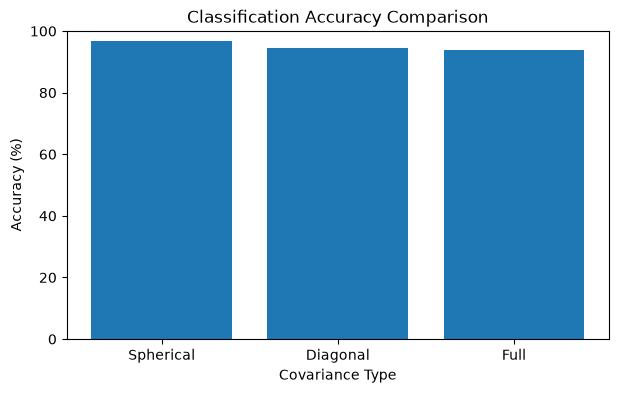

In [42]:
names = list(results.keys())
accuracies = [results[name]["accuracy"] for name in names]

plt.figure(figsize=(7, 4))
plt.bar(names, accuracies)

plt.xlabel("Covariance Type")
plt.ylabel("Accuracy (%)")
plt.title("Classification Accuracy Comparison")
plt.ylim(0, 100)

plt.show()

In [43]:
def mean_distortion(data, centroids):
    total = sum(
        calculate_distortion(point, centroids)
        for point in data
    )

    return total / len(data)


for name in covariance_types:

    train1 = datasets[name]["train1"]
    train2 = datasets[name]["train2"]

    centroids1 = kmeans_models[name]["Class 1"]
    centroids2 = kmeans_models[name]["Class 2"]

    distortion1 = mean_distortion(train1, centroids1)
    distortion2 = mean_distortion(train2, centroids2)

    print("\nCovariance Type:", name)
    print("Class 1 mean training distortion:", round(distortion1, 4))
    print("Class 2 mean training distortion:", round(distortion2, 4))


Covariance Type: Spherical
Class 1 mean training distortion: 1.9177
Class 2 mean training distortion: 1.9417

Covariance Type: Diagonal
Class 1 mean training distortion: 2.4261
Class 2 mean training distortion: 2.2564

Covariance Type: Full
Class 1 mean training distortion: 2.6827
Class 2 mean training distortion: 2.7801
